In [6]:
# ==============================================================================
# CELL 0: IMPORTS & CONFIGURATION
# ==============================================================================
import os
import glob
import numpy as np
import pandas as pd
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

def matplotlib_default_config():
    font = {'family': 'serif', 'weight': 'normal', 'size': 14}
    rcnew = {
        "mathtext.fontset": "cm",
        "text.usetex": False,
        'figure.frameon': True,
        'axes.linewidth': 2.,
        "axes.titlesize": 20,
        "axes.labelsize": 20,
        "legend.fontsize": 12,
        'legend.fancybox': True,
        'lines.linewidth': 2.5,
        'xtick.direction': 'in',
        'ytick.direction': 'in',
        'xtick.top': True,
        'ytick.right': True,
        'xtick.labelsize': 18,
        'ytick.labelsize': 18,
    }
    return font, rcnew

%matplotlib widget
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

In [7]:
# ==============================================================================
# CELL 1: LOAD DATA FOR MASK VS NO MASK COMPARISON
# ==============================================================================
HUBBLE_H = 0.6774
MASS_CONVERSION_FACTOR = 1e10 / HUBBLE_H

# --- ⚙️ CONTROLE PRINCIPAL ⚙️ ---
# Mude esta variável para 'TNG50-3' ou 'TNG50-2' quando quiser rodar os outros
TARGET_SIM = 'TNG50-2' 
# ---------------------------------

sim_suffix = TARGET_SIM.replace('TNG50-', '50_') # Converte 'TNG50-4' para '50_4'

# --- Simulation definitions (Mask vs No Mask) ---
SIM_CONFIGS = {
     'NO MASK': {
         'data_dir': f'data_for_variance_{sim_suffix}_fix',
         'pattern': f'{TARGET_SIM}_z3_*_DLAMode_Stratified_run*.pkl',
         'color': 'tab:blue',
         'ls': '-',
         'fill': 'cornflowerblue',
         'label': f'{TARGET_SIM} (NO MASK)',
    },
    'MASK': {
        'data_dir': f'data_for_variance_{sim_suffix}_mask',
        'pattern': f'{TARGET_SIM}_z3_*_DLAMode_Stratified_run*.pkl',
        'color': 'tab:orange',
        'ls': '--',
        'fill': 'sandybrown',
        'label': f'{TARGET_SIM} (MASK)',
    }
}

# --- Load runs for each simulation mode ---
sim_data = {}  # key: mode_name -> list of DataFrames (one per run)

for mode_name, cfg in SIM_CONFIGS.items():
    data_dir = cfg['data_dir']
    pattern  = os.path.join(data_dir, cfg['pattern'])
    files    = sorted(glob.glob(pattern))
    
    # Exclude any "Extended_" files
    files = [f for f in files if 'Extended_' not in os.path.basename(f)]

    if len(files) == 0:
        print(f"  [!] WARNING: No files found for {mode_name} in {data_dir}. Skipping.")
        continue

    runs = []
    for rf in files:
        df = pd.read_pickle(rf)
        df['r_mult_round']  = df['r_multiplier'].round(2)
        df['halo_mass_msun'] = df['halo_mass'] * MASS_CONVERSION_FACTOR
        runs.append(df)

    sim_data[mode_name] = runs
    print(f"{mode_name}: {len(runs)} runs loaded "
          f"({[len(r) for r in runs]} rows each)")

# --- Determine common impact parameters (union across sims) ---
ref_sim   = list(sim_data.keys())[0]
ref_radii = np.sort(sim_data[ref_sim][0]['r_mult_round'].unique())
print(f"\nReference impact parameters from {ref_sim} ({len(ref_radii)}):")
print(f"  {ref_radii}")

n_sims = len(sim_data)
print(f"\n{n_sims} modes loaded successfully for {TARGET_SIM}.")

NO MASK: 5 runs loaded ([231231, 231231, 231231, 231231, 231231] rows each)
MASK: 5 runs loaded ([231231, 231231, 231231, 231231, 231231] rows each)

Reference impact parameters from NO MASK (29):
  [0.000e+00 1.000e-02 2.000e-02 3.000e-02 4.000e-02 6.000e-02 8.000e-02
 1.000e-01 1.400e-01 1.900e-01 2.500e-01 3.400e-01 4.600e-01 6.100e-01
 8.200e-01 1.100e+00 1.470e+00 1.980e+00 2.650e+00 3.560e+00 4.770e+00
 6.400e+00 8.580e+00 1.151e+01 1.544e+01 2.072e+01 2.779e+01 3.728e+01
 5.000e+01]

2 modes loaded successfully for TNG50-2.


  Grid loaded: NO MASK (750,000 skewers)


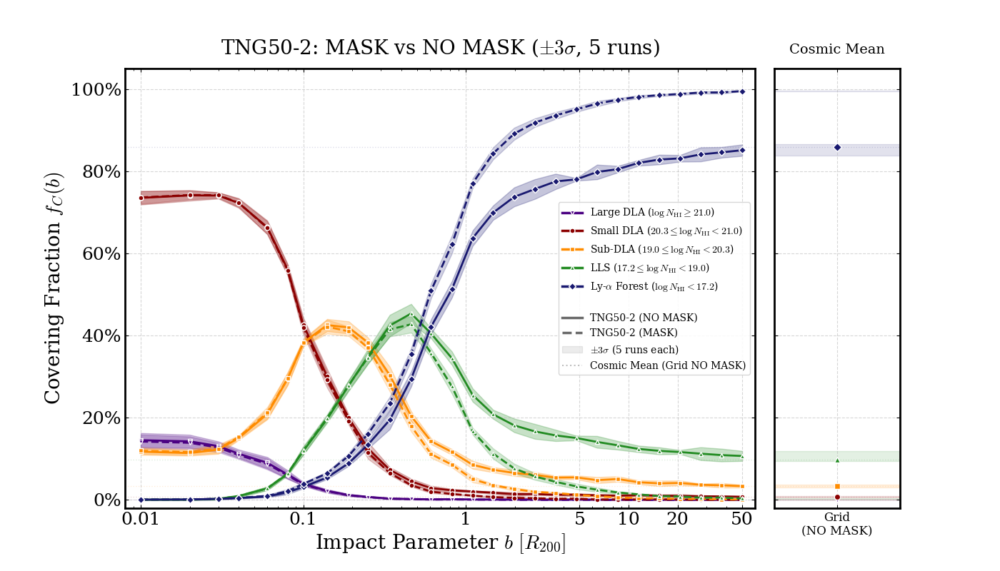

In [8]:
# ==============================================================================
# CELL 2: COVERING FRACTION — MASK VS NO MASK WITH GRID PANEL (b up to 50)      
# ==============================================================================
NSIGMA = 3    

cat_styles = {
    'Large_DLA': {'color': 'indigo',       'marker': 'v',
                  'label': r'Large DLA ($\log N_{\mathrm{HI}} \geq 21.0$)'},
    'Small_DLA': {'color': 'darkred',      'marker': 'o',
                  'label': r'Small DLA ($20.3 \leq \log N_{\mathrm{HI}} < 21.0$)'},
    'Sub_DLA':   {'color': 'darkorange',   'marker': 's',
                  'label': r'Sub-DLA ($19.0 \leq \log N_{\mathrm{HI}} < 20.3$)'},
    'LLS':       {'color': 'forestgreen',  'marker': '^',
                  'label': r'LLS ($17.2 \leq \log N_{\mathrm{HI}} < 19.0$)'},
    'Forest':    {'color': 'midnightblue', 'marker': 'D',
                  'label': r'Ly-$\alpha$ Forest ($\log N_{\mathrm{HI}} < 17.2$)'},
}

# --- Load Grid files (Only for NO MASK as requested) ---
GRID_FILES = {
    'NO MASK': f'data_grid/{TARGET_SIM}_z3_Grid_500x500_DLAMode.pkl'
}

bins_grid   = [0, 1.6e17, 1e19, 2e20, 1e21, np.inf]
labels_grid = ['Forest', 'LLS', 'Sub_DLA', 'Small_DLA', 'Large_DLA']

grid_fractions = {} 

for mode_name, gpath in GRID_FILES.items():
    if os.path.exists(gpath):
        df_g = pd.read_pickle(gpath)
        df_g['category'] = pd.cut(
            df_g['total_col_den'], bins=bins_grid, labels=labels_grid, right=False
        )
        total = len(df_g)
        counts = df_g['category'].value_counts(sort=False)
        grid_fractions[mode_name] = {cat: counts.get(cat, 0) / total for cat in labels_grid}
        print(f"  Grid loaded: {mode_name} ({total:,} skewers)")
    else:
        print(f"  [!] Grid file not found for {mode_name}: {gpath}")

# --- Compute fractions per run ---
def compute_fractions_per_run(runs, radii):
    fracs = {cat: [] for cat in cat_styles}
    for df_run in runs:
        run_fracs = {cat: [] for cat in cat_styles}
        for b_val in radii:
            df_b = df_run[df_run['r_mult_round'] == b_val]
            tot  = len(df_b)
            if tot > 0:
                nhi = df_b['log_n_hi']
                run_fracs['Large_DLA'].append(len(nhi[nhi >= 21.0]) / tot)
                run_fracs['Small_DLA'].append(len(nhi[(nhi >= 20.3) & (nhi < 21.0)]) / tot)
                run_fracs['Sub_DLA'].append(len(nhi[(nhi >= 19.0) & (nhi < 20.3)]) / tot)
                run_fracs['LLS'].append(len(nhi[(nhi >= 17.2) & (nhi < 19.0)]) / tot)
                run_fracs['Forest'].append(len(nhi[nhi < 17.2]) / tot)
            else:
                for cat in cat_styles:
                    run_fracs[cat].append(0.0)
        for cat in cat_styles:
            fracs[cat].append(run_fracs[cat])
    for cat in cat_styles:
        fracs[cat] = np.array(fracs[cat])
    return fracs

sim_fractions = {}
for mode_name, runs in sim_data.items():
    radii = np.sort(runs[0]['r_mult_round'].unique())
    sim_fractions[mode_name] = {
        'radii': radii,
        'fracs': compute_fractions_per_run(runs, radii),
    }

# --- Alpha Mapping for variance shading ---
alpha_map = {
    'NO MASK': 0.25,
    'MASK': 0.20,
}

# --- PLOT ---
fig_cov, (ax_main, ax_grid) = plt.subplots(
    1, 2, figsize=(14, 8),
    sharey=True,
    gridspec_kw={'width_ratios': [5, 1], 'wspace': 0.05},
)

# ---- Main panel: profiles ----
for cat, cstyle in cat_styles.items():
    for mode_name, cfg in SIM_CONFIGS.items():
        if mode_name not in sim_fractions:
            continue

        radii = sim_fractions[mode_name]['radii']
        data  = sim_fractions[mode_name]['fracs'][cat]  # (n_runs, n_radii)

        mean_f = np.mean(data, axis=0)
        std_f  = np.std(data, axis=0)

        ls = cfg['ls']
        shade_alpha = alpha_map.get(mode_name, 0.15)

        # Only positive radii for log scale
        mask   = radii > 0
        r_plot = radii[mask]
        m_plot = mean_f[mask]
        s_plot = std_f[mask]

        # ±Nσ shading
        ax_main.fill_between(
            r_plot,
            np.clip(m_plot - NSIGMA * s_plot, 0, None),
            np.clip(m_plot + NSIGMA * s_plot, None, 1),
            color=cstyle['color'], alpha=shade_alpha, zorder=1,
        )

        # Mean line
        ax_main.plot(
            r_plot, m_plot,
            color=cstyle['color'], lw=2.0, ls=ls,
            marker=cstyle['marker'], ms=5, mec='white', zorder=3,
        )

    # Cosmic-mean dotted line spanning main panel
    for mode_name in grid_fractions:
        gval = grid_fractions[mode_name].get(cat, None)
        if gval is not None:
            ax_main.axhline(gval, color=cstyle['color'], ls=':', alpha=0.15, lw=1.0, zorder=0)
            break  

# ---- Side panel: Grid cosmic means ----
sim_x_map = {'NO MASK': 0} # Só temos o grid da NO MASK

for cat, cstyle in cat_styles.items():
    for mode_name, gf in grid_fractions.items():
        gval = gf.get(cat, None)
        if gval is None:
            continue

        x_pos = sim_x_map[mode_name]
        mkr   = cstyle['marker']

        # Marker point
        ax_grid.plot(
            x_pos, gval,
            color=cstyle['color'], marker=mkr,
            ms=6, mec='white', zorder=3,
        )

    # Extend the last skewer-run variance into the side panel (for both mask and no mask)
    for mode_name, cfg in SIM_CONFIGS.items():
        if mode_name not in sim_fractions:
            continue
        data = sim_fractions[mode_name]['fracs'][cat]
        last_mean = np.mean(data, axis=0)[-1]
        last_std  = np.std(data, axis=0)[-1]
        shade_alpha = alpha_map.get(mode_name, 0.15)
        
        # Determine filling hatch/style if we want to visually separate them on the side panel
        # We will overlap them smoothly by using low alphas
        ax_grid.axhspan(
            np.clip(last_mean - NSIGMA * last_std, 0, None),
            np.clip(last_mean + NSIGMA * last_std, None, 1),
            color=cstyle['color'], alpha=shade_alpha * 0.5, zorder=0,
        )

    # Dotted horizontal lines in grid panel
    for mode_name in grid_fractions:
        gval = grid_fractions[mode_name].get(cat, None)
        if gval is not None:
            ax_grid.axhline(gval, color=cstyle['color'], ls=':', alpha=0.15, lw=1.0, zorder=0)
            break

# ---- Aesthetics: main panel ----
ax_main.grid(True, ls='--', alpha=0.5)
ax_main.set_xscale('log')
ax_main.set_ylim(-0.02, 1.05)
ax_main.set_xlim(0.008, 60)
ax_main.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0))

ax_main.set_xticks([0.01, 0.1, 1.0, 5.0, 10.0, 20.0, 50.0])
ax_main.set_xticklabels(['0.01', '0.1', '1', '5', '10', '20', '50'])

ax_main.set_xlabel(r'Impact Parameter $b \ [R_{200}]$')
ax_main.set_ylabel(r'Covering Fraction $f_C(b)$')
ax_main.set_title(
    rf'{TARGET_SIM}: MASK vs NO MASK ($\pm{NSIGMA}\sigma$, 5 runs)',
    pad=15,
)

# ---- Aesthetics: side panel ----
ax_grid.grid(True, ls='--', alpha=0.5)
ax_grid.set_xlim(-0.5, 0.5)
ax_grid.set_xticks([0])
ax_grid.set_xticklabels(['Grid\n(NO MASK)'], fontsize=12)
ax_grid.set_title('Cosmic Mean', pad=15, fontsize=14)

# ---- Composite legend ----
legend_cat = [
    Line2D([0], [0], color=c['color'], lw=2.5, marker=c['marker'],
           ms=5, mec='white', label=c['label'])
    for c in cat_styles.values()
]
legend_cat.append(Line2D([0], [0], color='none', label=' '))

legend_sim = [
    Line2D([0], [0], color='dimgray', lw=2.5, ls=cfg['ls'],
           label=cfg['label'])
    for mode_name, cfg in SIM_CONFIGS.items()
    if mode_name in sim_data
]

legend_sim.append(
    patches.Patch(facecolor='gray', alpha=0.15, edgecolor='gray',
                  label=rf'$\pm {NSIGMA}\sigma$ (5 runs each)')
)
legend_sim.append(
    Line2D([0], [0], color='gray', ls=':', alpha=0.5, lw=1.5,
           label='Cosmic Mean (Grid NO MASK)')
)

ax_main.legend(
    handles=legend_cat + legend_sim, loc='center right',
    frameon=True, fontsize=10, edgecolor='lightgray',
    facecolor='white', framealpha=0.9,
)

plt.show()

Ridgeline impact parameters (18): [0.0, 0.01, 0.02, 0.03, 0.04, 0.06, 0.08, 0.1, 0.14, 0.19, 0.25, 0.34, 0.46, 0.61, 0.82, 1.1, 1.47, 1.98]


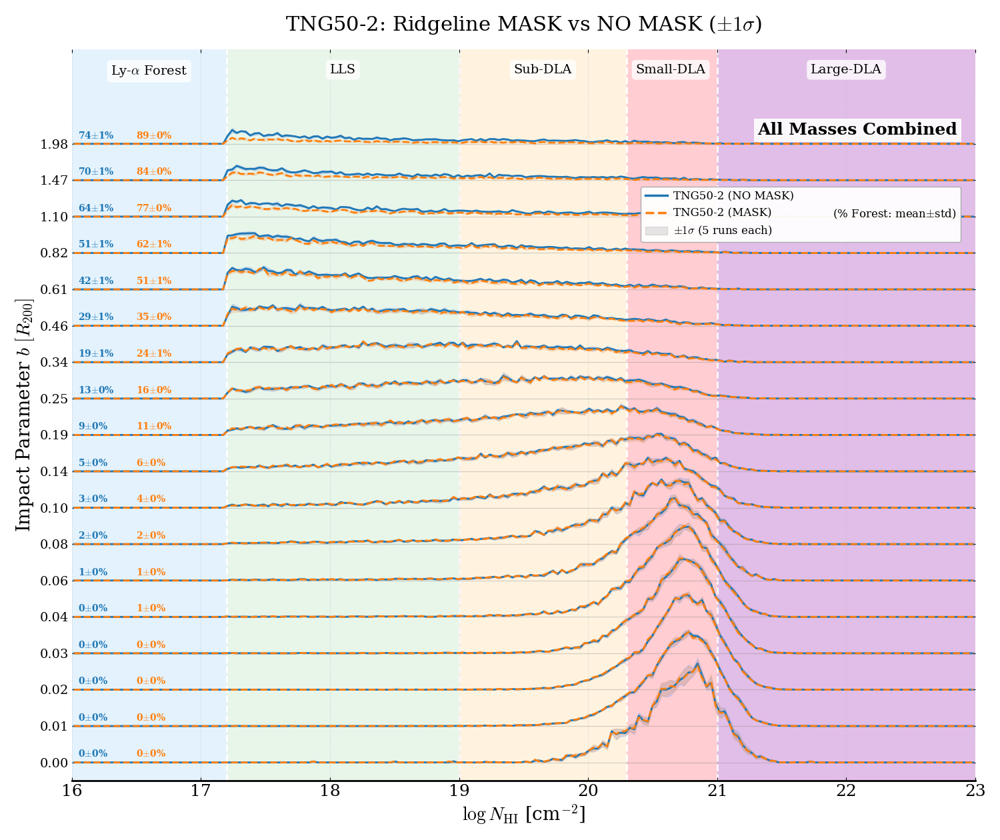

In [9]:
# ==============================================================================
# CELL 3: RIDGELINE — ALL MASSES COMBINED (MASK vs NO MASK)
# ==============================================================================
c_forest   = '#E3F2FD'
c_lls      = '#E8F5E9'
c_subdla   = '#FFF3E0'
c_smalldla = '#FFCDD2'
c_largedla = '#E1BEE7'

overlap_factor = 1.8
NSIGMA_RIDGE   = 1  

num_bins  = 200
hist_bins = np.linspace(16.0, 23.0, num_bins + 1)
x_hist    = (hist_bins[:-1] + hist_bins[1:]) / 2
bin_width = hist_bins[1] - hist_bins[0]

# Estilos dinâmicos do Ridgeline baseados no SIM_CONFIGS
SIM_RIDGE_STYLES = {
    'NO MASK': {'color': SIM_CONFIGS['NO MASK']['color'], 'fill': SIM_CONFIGS['NO MASK']['fill'], 'ls': SIM_CONFIGS['NO MASK']['ls']},
    'MASK':    {'color': SIM_CONFIGS['MASK']['color'],    'fill': SIM_CONFIGS['MASK']['fill'],    'ls': SIM_CONFIGS['MASK']['ls']},
}

def density_hist(values, bins, tot_skewers):
    if len(values) < 2 or tot_skewers == 0:
        return np.zeros(len(bins) - 1)
    
    counts, _ = np.histogram(values, bins=bins)
    bw = bins[1] - bins[0]
    return counts / (tot_skewers * bw)

def paint_ridgeline_multi(ax, sim_data, selected_b, mass_low=None, mass_high=None,
                          title_text='', show_legend=True):
    ax.axvspan(16.0, 17.2, color=c_forest,   zorder=0)
    ax.axvspan(17.2, 19.0, color=c_lls,      zorder=0)
    ax.axvspan(19.0, 20.3, color=c_subdla,   zorder=0)
    ax.axvspan(20.3, 21.0, color=c_smalldla, zorder=0)
    ax.axvspan(21.0, 23.0, color=c_largedla, zorder=0)

    for xv in [17.2, 19.0, 20.3, 21.0]:
        ax.axvline(xv, color='white', ls='--', lw=2.0, zorder=0)

    text_y_pos = 0.98
    bbox_props = dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8, edgecolor="none")
    ax.text(16.60, text_y_pos, r'Ly-$\alpha$ Forest', transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=14, bbox=bbox_props, zorder=10)
    ax.text(18.10, text_y_pos, 'LLS', transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=14, bbox=bbox_props, zorder=10)
    ax.text(19.65, text_y_pos, 'Sub-DLA', transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=14, bbox=bbox_props, zorder=10)
    ax.text(20.64, text_y_pos, 'Small-DLA', transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=14, bbox=bbox_props, zorder=10)
    ax.text(22.0, text_y_pos, 'Large-DLA', transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=14, bbox=bbox_props, zorder=10)

    ax.grid(axis='x', ls=':', alpha=0.5)
    ax.grid(axis='y', visible=False)
    ax.spines['left'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

    y_ticks  = []
    y_labels = []

    for i_b, b_val in enumerate(selected_b):
        b_round = np.round(b_val, 2)
        y_base  = i_b

        y_ticks.append(y_base)
        y_labels.append(f"{b_val:.2f}")
        ax.axhline(y_base, color='gray', lw=1.0, alpha=0.3, zorder=1)

        text_offset = 0

        for mode_name, runs in sim_data.items():
            sty = SIM_RIDGE_STYLES.get(mode_name)

            hist_stack  = []
            forest_pcts = []

            for df_run in runs:
                if mass_low is not None and mass_high is not None:
                    df_mass = df_run[
                        (df_run['halo_mass_msun'] >= mass_low) &
                        (df_run['halo_mass_msun'] <  mass_high)
                    ]
                else:
                    df_mass = df_run

                df_b  = df_mass[df_mass['r_mult_round'] == b_round]
                tot   = len(df_b)
                valid = df_b[df_b['log_n_hi'] > 1.0]['log_n_hi'].values

                mask_hist = (valid >= 16.0) & (valid <= 23.0)
                hist_dens = density_hist(valid[mask_hist], hist_bins, tot)
                hist_stack.append(hist_dens)

                if tot > 0:
                    pct_all = len(df_b[df_b['log_n_hi'] < 17.2]) / tot * 100
                else:
                    pct_all = 0.0

                forest_pcts.append(pct_all)

            hist_stack = np.array(hist_stack)

            mean_hist = np.mean(hist_stack, axis=0)
            std_hist  = np.std(hist_stack, axis=0)

            mean_scaled = mean_hist * overlap_factor
            lo_scaled   = np.clip(mean_hist - NSIGMA_RIDGE * std_hist, 0, None) * overlap_factor
            hi_scaled   = (mean_hist + NSIGMA_RIDGE * std_hist) * overlap_factor

            # σ band
            ax.fill_between(
                x_hist, y_base + lo_scaled, y_base + hi_scaled,
                color=sty['fill'], alpha=0.25, zorder=i_b + 3,
            )

            # Mean line
            ax.plot(
                x_hist, y_base + mean_scaled,
                color=sty['color'], lw=2.0, ls=sty['ls'], zorder=i_b + 5,
            )

            mean_f = np.mean(forest_pcts)
            std_f  = np.std(forest_pcts)
            
            # Anotações laterais do Forest Fraction
            ax.text(
                16.05 + text_offset * 0.9, y_base + 0.15,
                rf"{mean_f:.0f}$\pm${std_f:.0f}%",
                color=sty['color'], fontsize=10, fontweight='bold', zorder=20,
            )
            text_offset += 0.5

    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels, fontsize=14)
    ax.set_xlim(16.0, 23.0)
    ax.set_ylim(-0.5, len(selected_b) - 1 + overlap_factor + 0.8)

    if title_text:
        ax.text(
            0.98, 0.90, title_text, transform=ax.transAxes,
            fontsize=18, ha='right', va='top', fontweight='bold',
            bbox=dict(facecolor='white', alpha=0.9, edgecolor='none'),
            zorder=30,
        )

    if show_legend:
        sim_lines = []
        for mode_name in sim_data.keys():
            sty = SIM_RIDGE_STYLES.get(mode_name)
            lbl = SIM_CONFIGS.get(mode_name, {}).get('label', mode_name)
            sim_lines.append(
                Line2D([0], [0], color=sty['color'], lw=2.5, ls=sty['ls'], label=lbl)
            )

        band_patch = patches.Patch(
            facecolor='gray', alpha=0.2, edgecolor='gray',
            label=rf'$\pm {NSIGMA_RIDGE}\sigma$ (5 runs each)',
        )
        spacer = Line2D([0], [0], marker='none', linestyle='none', label=' ')
        info_line = Line2D([0], [0], marker='none', linestyle='none',
                           label=r'(% Forest: mean$\pm$std)')

        all_handles = sim_lines + [band_patch, spacer, info_line]

        leg = ax.legend(
            handles=all_handles, loc='upper right', ncol=2,
            frameon=True, fontsize=12,
            bbox_to_anchor=(0.99, 0.82),
            facecolor='white', framealpha=0.95,
            edgecolor='darkgray', columnspacing=1.0, handletextpad=0.5,
        )
        leg.set_zorder(100)


SELECTED_B = sorted([b for b in ref_radii if 0.0 <= b <= 2.0])
n_sel = len(SELECTED_B)
print(f"Ridgeline impact parameters ({n_sel}): {SELECTED_B}")

fig_height = max(10, 0.70 * n_sel)
fig_ridge_all, ax_ridge_all = plt.subplots(figsize=(15, fig_height))

paint_ridgeline_multi(
    ax_ridge_all, sim_data, SELECTED_B,
    mass_low=None, mass_high=None,
    title_text='All Masses Combined',
    show_legend=True,
)

ax_ridge_all.set_xlabel(r"$\log N_{\rm HI}$ [cm$^{-2}$]", fontsize=20)
ax_ridge_all.set_ylabel(r'Impact Parameter $b \ [R_{200}]$', fontsize=20)
ax_ridge_all.set_title(
    rf'{TARGET_SIM}: Ridgeline MASK vs NO MASK ($\pm{NSIGMA_RIDGE}\sigma$)',
    pad=20, fontsize=22,
)

plt.tight_layout()
plt.show()

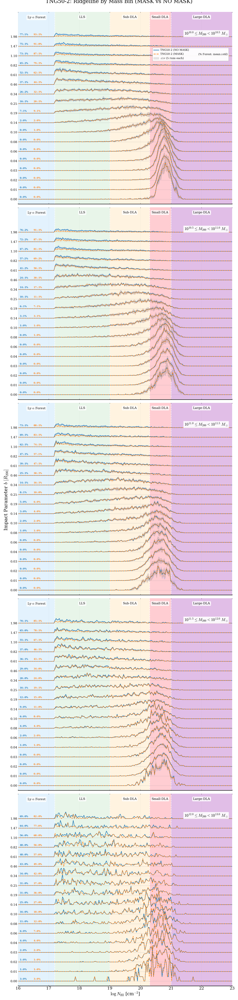

In [10]:
# ==============================================================================
# CELL 4: RIDGELINE — SPLIT BY MASS BIN
# ==============================================================================
mass_edges_ridge = [10**10.0, 10**10.5, 10**11.0, 10**11.5, 10**12.0, 10**13.0]
mass_labels_ridge = [
    r'$10^{10.0} \leq M_{200} < 10^{10.5} \; M_\odot$',
    r'$10^{10.5} \leq M_{200} < 10^{11.0} \; M_\odot$',
    r'$10^{11.0} \leq M_{200} < 10^{11.5} \; M_\odot$',
    r'$10^{11.5} \leq M_{200} < 10^{12.0} \; M_\odot$',
    r'$10^{12.0} \leq M_{200} < 10^{13.0} \; M_\odot$',
]
n_mass_bins = len(mass_labels_ridge)

fig_height_bin = max(8, 0.70 * n_sel)
fig_ridge_mass, axes_ridge_mass = plt.subplots(
    n_mass_bins, 1,
    figsize=(15, fig_height_bin * n_mass_bins),
    sharex=True,
)
if n_mass_bins == 1:
    axes_ridge_mass = np.array([axes_ridge_mass])

for i_m in range(n_mass_bins):
    m_low  = mass_edges_ridge[i_m]
    m_high = mass_edges_ridge[i_m + 1]

    paint_ridgeline_multi(
        axes_ridge_mass[i_m], sim_data, SELECTED_B,
        mass_low=m_low, mass_high=m_high,
        title_text=mass_labels_ridge[i_m],
        show_legend=(i_m == 0),
    )

axes_ridge_mass[-1].set_xlabel(r"$\log N_{\rm HI}$ [cm$^{-2}$]", fontsize=20)
fig_ridge_mass.text(
    0.015, 0.5,
    r'Impact Parameter $b \ [R_{200}]$',
    va='center', rotation='vertical', fontsize=22,
)
fig_ridge_mass.suptitle(
    rf'{TARGET_SIM}: Ridgeline by Mass Bin (MASK vs NO MASK)',
    fontsize=24, y=1.001,
)

plt.tight_layout(rect=[0.03, 0.0, 1, 1])
plt.show()